# Ni: combined easyXRD integration and Rietveld notebook

This notebook combines the three notebooks in this folder. Run **Restart Kernel and Run All**
using the user's Pixi Python environment, `/home/mt/mpixi/.pixi/envs/default/bin/python`,
with this folder as the working directory. All demonstrations run by default; no downloads
or API keys are needed. Generated files go to `Ni_combined_results/`.

The alternatives teach different API paths. They are **not a benchmark**, and no route is
ranked or selected by its fit residual. Each starts with its own easyXRD/GSAS-II object.

| Source notebook | Methods retained here |
|---|---|
| `Ni_Rietveld_Refinement_a.ipynb` | Detector/mask inspection, focused cake integration, XY export, phase overlay, background 5 → 10 → 15, fixed-reference size/strain refinement, Le Bail → Rietveld, Uiso, GPX and plot export |
| `Ni_Rietveld_refinement_b.ipynb` | Environment/provenance records, finite-pixel mask, direct 1D integration, diagnostic azimuthal errors, explicit relative weights, indexed CIF reflections, Rietveld from the outset, U/V/W and X/Y, physical Uiso check, GSAS-II result access, profile/CIF export and reopen checks |
| `Ni_Rietveld_refinement_c.ipynb` | Wide-range inspection followed by focused integration, sequential U → V → W → Zero, repeated background/cell passes, Le Bail transition, reusable all-in-one workflow |

Corrections carried into the combined version: easyXRD `mode="xy"` exports **2θ**, while
`mode="qxy"` exports **q**; fit statistics come from the current GSAS-II project;
negative image values are retained and visualized safely. Source claims about the origin of
the instrument calibration are not assumed. A Le Bail fit is labeled as such until the
explicit transition to structural Rietveld refinement.

## 1. Environment, inputs, and output locations

Set writable cache and scratch locations before importing easyXRD. The existing input files
and source notebooks are checked by SHA-256 at the end. A new scratch directory is created
by easyXRD for each model; rerunning the notebook refreshes named exports.

In [1]:
import os
import sys
import json
import copy
import hashlib
import importlib.metadata as metadata
from pathlib import Path

BASE = Path.cwd().resolve()
INPUTS = ['Ni.tiff', '_calibration.poni', '_mask.edf', 'Ni.cif', '_instrument_parameters.gpx']
SOURCES = ['Ni_Rietveld_Refinement_a.ipynb', 'Ni_Rietveld_refinement_b.ipynb',
           'Ni_Rietveld_refinement_c.ipynb']
missing = [name for name in INPUTS + SOURCES if not (BASE / name).is_file()]
if missing:
    raise FileNotFoundError(f'Run from the notebook directory. Missing files: {missing}')
OUT = BASE / 'Ni_combined_results'
OUT.mkdir(exist_ok=True)
for name in ['EASYXRD_SCRATCH', 'NUMBA_CACHE_DIR', 'MPLCONFIGDIR', 'IPYTHONDIR', 'XDG_CACHE_HOME']:
    location = OUT / {'EASYXRD_SCRATCH': 'gsas_work'}.get(name, '.' + name.lower())
    location.mkdir(exist_ok=True)
    os.environ[name] = str(location)
os.environ.setdefault('OMP_NUM_THREADS', '4')

from easyxrd import exrd, set_defaults
from easyxrd.utils import ensure_wx_importable
# Load GSAS-II's wx dependency before pyplot/Qt select a different fontconfig library.
# This imports wx only; it does not start a GUI application.
ensure_wx_importable()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
import fabio
import pyFAI
from GSASII import GSASIIscriptable as G2sc
from pymatgen.core import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from scipy.signal import find_peaks
from IPython.display import display, Markdown

# Also support rerunning this cell in a kernel that already imported easyXRD.
set_defaults('easyxrd_scratch_path', os.environ['EASYXRD_SCRATCH'])
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'figure.constrained_layout.use': True, 'font.size': 10})

def sha256(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

original_hashes = {name: sha256(BASE / name) for name in INPUTS + SOURCES}
versions = {'python': sys.version, 'executable': sys.executable, 'GSASII_module': G2sc.__file__}
for package in ['easyxrd', 'pyFAI', 'fabio', 'numpy', 'scipy', 'pymatgen', 'GSAS-II']:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = 'distribution metadata unavailable; see module location'
print(json.dumps(versions, indent=2))
print(f'Output folder: {OUT}')

{
  "python": "3.14.8 | packaged by conda-forge | (main, Oct 12 2026, 17:35:27) [GCC 15.3.0]",
  "executable": "/home/mt/mpixi/.pixi/envs/default/bin/python",
  "GSASII_module": "/home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII/GSASIIscriptable.py",
  "easyxrd": "2026.9.20",
  "pyFAI": "2026.9.0",
  "fabio": "2026.6.0",
  "numpy": "2.5.4",
  "scipy": "1.18.1",
  "pymatgen": "2026.9.24",
  "GSAS-II": "2.0.0"
}
Output folder: /home/mt/repos/easyXRD_with_agents/00-Ni/_combined_with_GPT-6.1-Sol-High/Ni_combined_results


## 2. Inspect the detector, mask, and supplied calibration (A, B, C)

Nonzero mask pixels and nonfinite detector pixels are excluded. Finite negative pixels are
retained. The linear view follows A/B, and the signed logarithmic view adapts C's log display
without applying `log1p` to negative intensities. Downsampling affects only these displays.

Image: (3888, 3072), float32; range: -146 to 6.9e+03
Excluded pixels: 54,514 / 11,943,936 (0.456%)
Wavelength: 0.179900 Å; detector distance: 0.599497 m
# Nota: C-Order, 1 refers to the Y axis, 2 to the X axis
# Calibration done on Tue Sep 22 13:05:47 2026
poni_version: 2.1
Detector: Dexela2923
Detector_config: {"pixel1": 7.5e-05, "pixel2": 7.5e-05, "orientation": 3}
Distance: 0.5994971710951388
Poni1: 0.14065698666183532
Poni2: 0.09934596997307191
Rot1: -0.02386657077923864
Rot2: 0.007321294812142471
Rot3: 0.0
Wavelength: 1.799e-11
# Calibrant: Ni
# Image: fabio:///home/mt/repos/agent-work/assignments/Ni/20260731-131854_81DFC0_count_Ni-75-150_moving.tiff



,parameter,supplied_value
0,Type,PXC
1,Bank,1.0
2,Lam,0.1799
3,Polariz.,0.0
4,Azimuth,0.0
5,Zero,0.0
6,U,-29.429568
7,V,13.791336
8,W,0.870891
9,X,0.07517


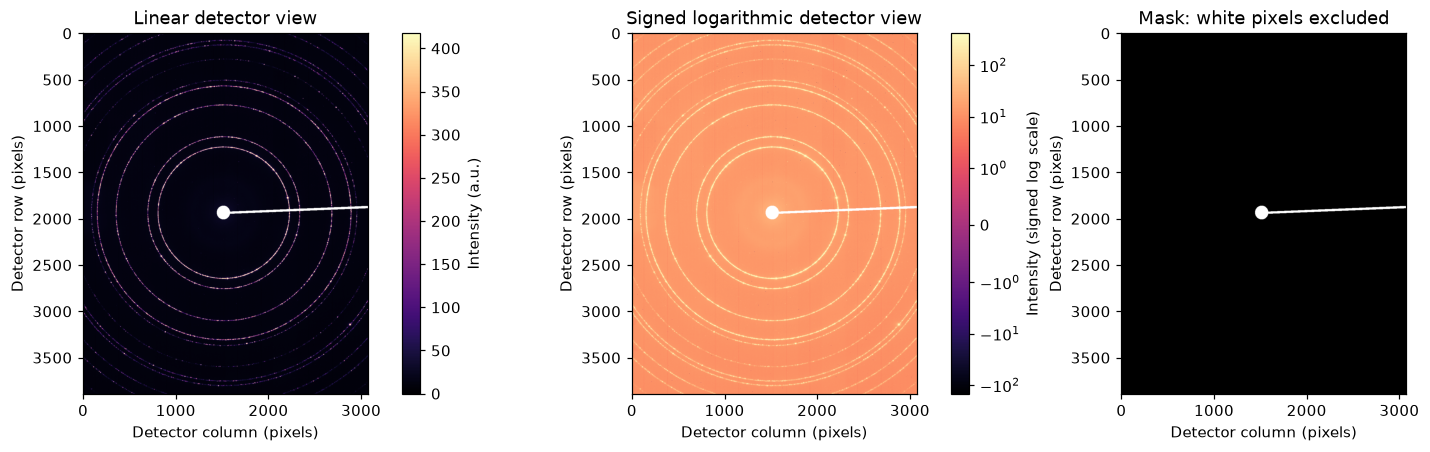

In [2]:
with fabio.open(str(BASE / 'Ni.tiff')) as handle:
    image = handle.data.astype(np.float32)
with fabio.open(str(BASE / '_mask.edf')) as handle:
    provided_mask = handle.data != 0
assert image.shape == provided_mask.shape, 'Image and mask dimensions must match.'
mask = provided_mask | ~np.isfinite(image)
finite_pixels = image[~mask]
assert finite_pixels.size > 0
ai = pyFAI.load(str(BASE / '_calibration.poni'))
wavelength = float(ai.wavelength * 1e10)
reference = G2sc.G2Project(gpxfile=str(BASE / '_instrument_parameters.gpx'))
assert len(reference.histograms()) == 1, 'Choose the reference histogram explicitly if multiple are supplied.'
reference_inst = copy.deepcopy(reference.histograms()[0].data['Instrument Parameters'][0])
assert np.isclose(reference_inst['Lam'][1], wavelength, atol=1e-6)
print(f'Image: {image.shape}, {image.dtype}; range: {finite_pixels.min():.3g} to {finite_pixels.max():.3g}')
print(f'Excluded pixels: {mask.sum():,} / {mask.size:,} ({100 * mask.mean():.3f}%)')
print(f'Wavelength: {wavelength:.6f} Å; detector distance: {ai.dist:.6f} m')
print((BASE / '_calibration.poni').read_text())
display(pd.DataFrame([{'parameter': k, 'supplied_value': v[1]} for k, v in reference_inst.items()]))

view = np.ma.array(image[::3, ::3], mask=mask[::3, ::3])
extent = (0, image.shape[1], image.shape[0], 0)
upper = float(np.percentile(finite_pixels, 99.5))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
im = axes[0].imshow(view, extent=extent, cmap='magma', vmin=0, vmax=upper)
fig.colorbar(im, ax=axes[0], label='Intensity (a.u.)')
axes[0].set_title('Linear detector view')
im = axes[1].imshow(view, extent=extent, cmap='magma',
                    norm=SymLogNorm(linthresh=1, vmin=min(float(finite_pixels.min()), 0), vmax=upper))
fig.colorbar(im, ax=axes[1], label='Intensity (signed log scale)')
axes[1].set_title('Signed logarithmic detector view')
axes[2].imshow(mask[::3, ::3], extent=extent, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Mask: white pixels excluded')
for ax in axes:
    ax.set(xlabel='Detector column (pixels)', ylabel='Detector row (pixels)')
fig.savefig(OUT / 'Ni_detector_and_mask.png', dpi=160)
plt.show()
del finite_pixels

## 3. First integration approach: cake → azimuthal average (A, C)

C first inspects a wide q range, then reintegrates over the useful signal region. Here the
wide inspection spans 0.5–10.4 Å⁻¹ and the focused example follows A's 1.5–9.5 Å⁻¹ range.
The `integrate2d=True` path stores both the cake and its mean over occupied azimuth bins.
Masked and uncovered bins are omitted from that mean. The common refinement range used
below is 2.5–9.5 Å⁻¹. These choices are examples, not an optimization search.

Wide inspection and focused cake integration completed.


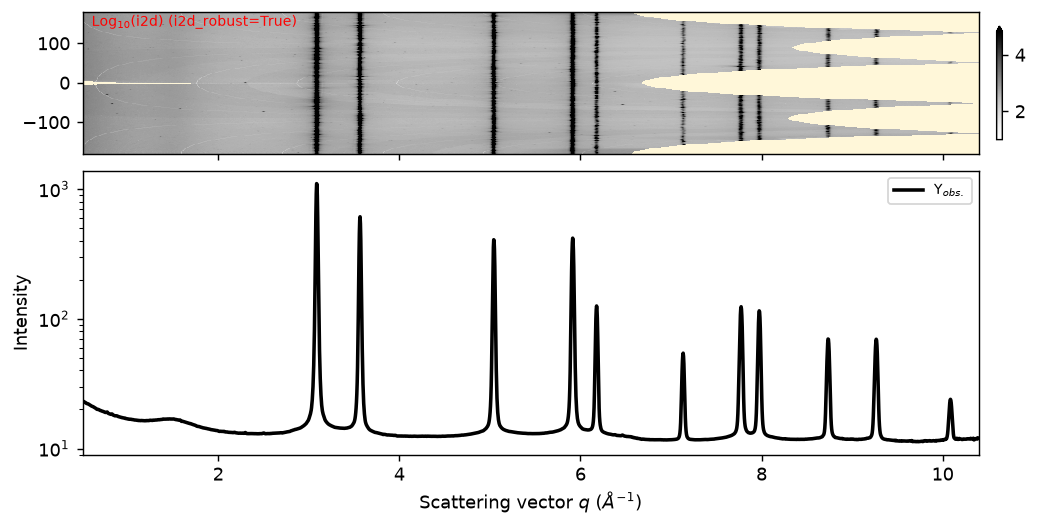

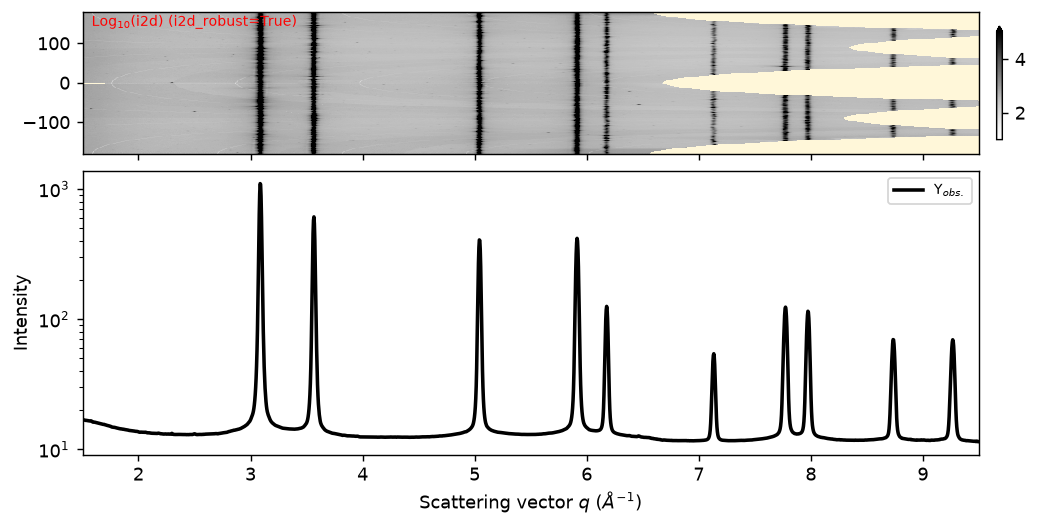

In [3]:
Q_RANGE = [0.5, 10.4]
FOCUSED_RANGE = [1.5, 9.5]
FIT_RANGE = [2.5, 9.5]
DELTA_Q = 0.004
METHOD = ('bbox', 'csr', 'cython')  # CPU integration; no GPU dependency

wide_cake = exrd(i1d_ylogscale=True, i2d_logscale=True)
wide_cake.load_xrd_data(
    from_tiff_file=str(BASE / 'Ni.tiff'), ai=ai, mask=mask,
    integrate2d=True, radial_range=Q_RANGE, delta_q=DELTA_Q,
    npt_azimuthal=180, method=METHOD, ds_attrs={}, plot=True,
)
cake_sample = exrd(i1d_ylogscale=True, i2d_logscale=True)
cake_sample.load_xrd_data(
    from_tiff_file=str(BASE / 'Ni.tiff'), ai=ai, mask=mask,
    integrate2d=True, radial_range=FOCUSED_RANGE, delta_q=DELTA_Q,
    npt_azimuthal=180, method=METHOD, ds_attrs={}, plot=True,
)
assert np.all(np.isfinite(cake_sample.ds.i1d.values))
print('Wide inspection and focused cake integration completed.')

## 4. Another integration approach: direct 1D pixel integration (B)

Set `integrate2d=False` to integrate contributing detector pixels directly into radial bins.
This weights contributing pixels differently from a mean of cake azimuth bins when coverage
varies. Both paths are retained as demonstrations, without scoring their results.

Solid-angle correction is enabled in both paths. No extra dark, flat, median-filter, or
polarization correction is introduced. B's azimuthal standard error is exported separately
as a diagnostic; it is not a calibrated detector counting uncertainty.

Direct integration and azimuthal-error diagnostic completed.


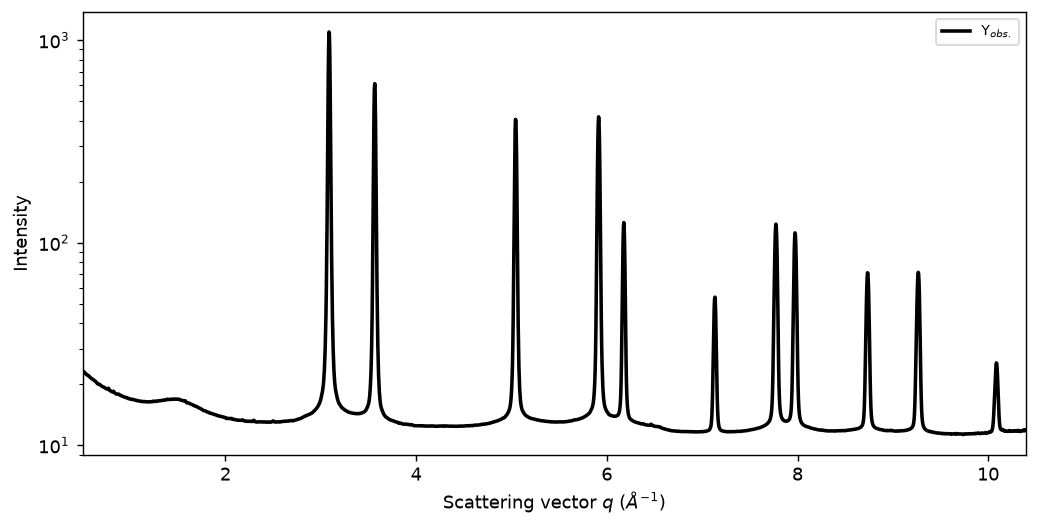

In [4]:
direct_sample = exrd(i1d_ylogscale=True)
direct_sample.load_xrd_data(
    from_tiff_file=str(BASE / 'Ni.tiff'), ai=ai, mask=mask,
    integrate2d=False, radial_range=Q_RANGE, delta_q=DELTA_Q,
    method=METHOD, ds_attrs={}, plot=True,
)
q = direct_sample.ds.i1d.radial.values.astype(float)
y = direct_sample.ds.i1d.values.astype(float)
two_theta = np.degrees(2 * np.arcsin(q * wavelength / (4 * np.pi)))
azimuthal_diagnostic = ai.integrate1d(
    image, npt=len(q), radial_range=Q_RANGE, mask=mask,
    unit='q_A^-1', method=METHOD, error_model='azimuthal',
    correctSolidAngle=True, polarization_factor=None,
)
assert np.allclose(q, azimuthal_diagnostic.radial, atol=1e-6)
assert np.allclose(y, azimuthal_diagnostic.intensity, rtol=1e-6)
assert np.all(np.isfinite(y)) and np.all(azimuthal_diagnostic.count > 0)
sigma_proxy = np.sqrt(np.maximum(y, 1.0))
pd.DataFrame({
    'q_A^-1': q, 'two_theta_deg': two_theta, 'intensity_au': y,
    'sigma_weight_proxy': sigma_proxy,
    'sigma_azimuthal_diagnostic': azimuthal_diagnostic.sigma,
    'effective_pixel_count': azimuthal_diagnostic.count,
}).to_csv(OUT / 'Ni_direct_integrated_profile.csv', index=False)
print('Direct integration and azimuthal-error diagnostic completed.')

### 4.1 Export in q, 2θ, and XYE formats; reload a text profile (A, B)

The public easyXRD exporter supports `qxy` and `xy` for q and 2θ respectively. The third XYE
column below is `sqrt(max(I, 1))`, an approximate weight proxy. None of these exports has a
background subtracted. The text-reload example supplies the wavelength and units explicitly.

In [5]:
for label, integrated in [('cake', cake_sample), ('direct', direct_sample)]:
    integrated.export_i1d_to(str(OUT / f'Ni_{label}_q.xy'), mode='qxy',
                              fmt='%.9e %.9e', header=True)
    integrated.export_i1d_to(str(OUT / f'Ni_{label}_2theta.xy'), mode='xy',
                              fmt='%.9e %.9e', header=True)
np.savetxt(OUT / 'Ni_direct_2theta.xye', np.c_[two_theta, y, sigma_proxy],
           header='two_theta_deg intensity_au sigma_weight_proxy; sigma is NOT measured uncertainty')
reloaded = exrd()
reloaded.load_xrd_data(
    from_txt_file=str(OUT / 'Ni_direct_2theta.xy'), txt_file_radial_unit='tth',
    txt_file_wavelength_in_angstrom=wavelength, radial_range=FIT_RANGE, plot=False,
)
selected = direct_sample.ds.i1d.sel(radial=slice(*FIT_RANGE))
assert np.allclose(reloaded.ds.i1d.radial, selected.radial, atol=1e-6)
assert np.allclose(reloaded.ds.i1d.values, selected.values, rtol=1e-6)
print('q/2θ/XYE exports and 2θ text reload checked.')

q/2θ/XYE exports and 2θ text reload checked.


## 5. Two phase-inspection styles (A, B, C)

First use easyXRD's built-in CIF reflection overlay. Then use pymatgen for an explicit hkl
table, including degenerate reflections, and SciPy for a simple nearest-bin peak annotation.
The annotations are illustrative: no automatic phase search or purity assessment is made.

,hkl,q_CIF_A^-1,nearest_peak_bin_A^-1,two_theta_CIF_deg,relative_CIF_intensity
0,"(1, 1, 1)",3.08681,3.086,5.06554,100.00000
1,"(2, 0, 0)",3.56435,3.566,5.84982,49.17456
2,"(2, 2, 0)",5.04075,5.042,8.27649,32.23220
3,"(3, 1, 1)",5.91080,5.914,9.70822,36.44297
4,"(2, 2, 2)",6.17363,6.178,10.14101,10.30463
5,"(4, 0, 0)",7.12869,7.134,11.71495,4.36242
6,"(3, 3, 1)",7.76831,7.774,12.77026,12.21386
7,"(4, 2, 0)",7.97012,7.974,13.10345,10.97284
8,"(4, 2, 2)",8.73083,8.734,14.36040,7.53216
9,"(5, 1, 1) / (3, 3, 3)",9.26044,9.266,15.23653,7.95078


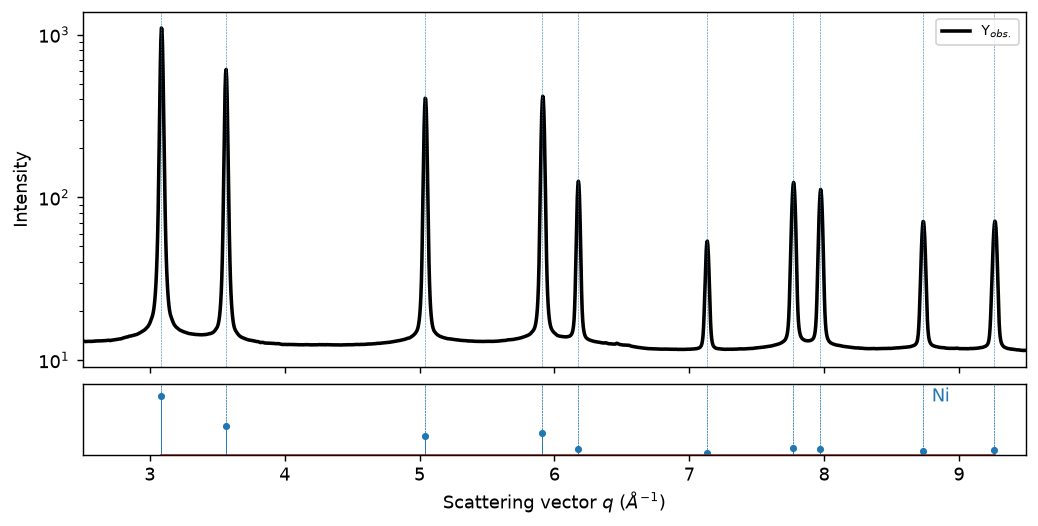

In [6]:
phase_view = exrd(i1d_ylogscale=True)
phase_view.load_xrd_data(from_da_i1d=selected.copy(deep=True), plot=False)
phase_view.load_phases([{'cif': str(BASE / 'Ni.cif'), 'label': 'Ni'}], plot=True)
initial_structure = Structure.from_file(BASE / 'Ni.cif')
calculator = XRDCalculator(wavelength=wavelength)
fit_two_theta = np.degrees(2 * np.arcsin(np.asarray(selected.radial) * wavelength / (4 * np.pi)))
predicted = calculator.get_pattern(initial_structure,
    two_theta_range=(float(fit_two_theta.min()), float(fit_two_theta.max())))
predicted_q = 4 * np.pi * np.sin(np.radians(predicted.x) / 2) / wavelength
peak_bins, _ = find_peaks(y, prominence=10, distance=20)
rows = []
for position, angle, intensity, hkls in zip(predicted_q, predicted.x, predicted.y, predicted.hkls):
    nearby = peak_bins[np.abs(q[peak_bins] - position) < 0.10]
    measured = float(q[nearby[np.argmin(abs(q[nearby] - position))]]) if len(nearby) else np.nan
    rows.append({'hkl': ' / '.join(str(h['hkl']) for h in hkls),
                 'q_CIF_A^-1': position, 'nearest_peak_bin_A^-1': measured,
                 'two_theta_CIF_deg': angle, 'relative_CIF_intensity': intensity})
phase_matches = pd.DataFrame(rows)
phase_matches.to_csv(OUT / 'Ni_CIF_reflections.csv', index=False)
display(phase_matches.round(5))

## 6. Shared model setup and result helpers

Every route imports the supplied instrument parameters into a new project. Normalization
is shown in A/C; B retains the input intensity scale. For every model, histogram weights
are set explicitly to `1 / max(yobs, 1)` on **that model's intensity scale**. These are
relative weights, so GOF and formal fit errors are not absolute statistical uncertainty.

easyXRD's refinement helpers normally clear the parameter flags after each call. Where a
joint refinement is intended, `set_to_false_after_refinement=False` keeps them active.
The helper below handles a negative unconstrained Uiso trial by fixing it to zero and
refitting, as in B; the trial is recorded and never silently presented as a thermal result.

In [7]:
def make_model(profile, *, normalize, lebail, refine_sample_broadening=False):
    model = exrd(i1d_ylogscale=False)
    model.load_xrd_data(from_da_i1d=profile.sel(radial=slice(*FIT_RANGE)).copy(deep=True), plot=False)
    model.load_phases([{'cif': str(BASE / 'Ni.cif'), 'label': 'Ni'}], plot=False)
    model.setup_gsas2_refiner(
        instprm_from_gpx=str(BASE / '_instrument_parameters.gpx'),
        normalize=normalize, do_1st_refinement=False, plot=False,
    )
    # B stays in Rietveld from its first optimizer call. A/C first seed reflections
    # in structural mode, as easyXRD's default setup does before enabling Le Bail.
    model.set_LeBail(to=False, refine=False, plot=False)
    histogram = model.gpx.histograms()[0]
    for key, entry in reference_inst.items():
        if isinstance(entry[1], (int, float, np.number)):
            assert np.isclose(histogram.data['Instrument Parameters'][0][key][1], entry[1])
    histogram.data['data'][1][2] = 1.0 / np.maximum(histogram.getdata('yobs'), 1.0)
    phase = model.gpx.phases()[0]
    # Preserve GSAS-II's starting size/strain values for A, as in its source notebook.
    # B/C instead use fixed reference contributions while fitting profile coefficients.
    hap = phase.data['Histograms'][histogram.name]
    if not refine_sample_broadening:
        hap['Size'][1][0] = 10.0
        hap['Mustrain'][1][0] = 0.0
    phase.data['Atoms'][0][10] = 0.0
    phase.atom(phase.data['Atoms'][0][0]).refinement_flags = ''
    if lebail:
        model.refine(update_ds=False, update_ds_phases=False, update_phases=False)
        model.set_LeBail(to=True, refine=False, plot=False)
    model.gpx_saver()
    return model

def fit_site_displacement(model):
    model.refine_site_property(site_ind=0, refinement_flags='U',
                              set_to_false_after_refinement=False, plot=False)
    trial = float(model.gpx.phases()[0].data['Atoms'][0][10])
    if not np.isfinite(trial):
        raise ValueError('The Uiso trial did not produce a finite value.')
    if trial < 0:
        model.gpx.phases()[0].data['Atoms'][0][10] = 0.0
        model.clear_site_property_refinement(site_ind=0)
        print(f'Uiso trial {trial:.6g} Å² is negative: fix Uiso=0 and refit.')
        print(model.refine())
    else:
        print(f'Nonnegative Uiso trial retained: {trial:.6g} Å².')
    model.ds.attrs['combined_Uiso_trial_A2'] = trial
    return trial

def validate_model(model):
    histogram = model.gpx.histograms()[0]
    phase = model.gpx.phases()[0]
    assert phase.data['Histograms'][histogram.name]['LeBail'] is False
    assert not model.gpx['Covariance']['data']['Rvals'].get('Aborted', False)
    arrays = np.column_stack([histogram.getdata(k) for k in
                              ['x', 'yobs', 'ycalc', 'background', 'yweight']])
    assert len(arrays) > 0 and np.all(np.isfinite(arrays))
    assert np.all(arrays[:, 4] > 0)
    assert np.allclose(arrays[:, 4], 1 / np.maximum(arrays[:, 1], 1), rtol=1e-6)
    assert np.isfinite(phase.get_cell()['length_a']) and phase.get_cell()['length_a'] > 0
    assert phase.data['Atoms'][0][10] >= 0
    hap = phase.data['Histograms'][histogram.name]
    assert np.isfinite(hap['Size'][1][0]) and hap['Size'][1][0] > 0
    assert np.isfinite(hap['Mustrain'][1][0]) and hap['Mustrain'][1][0] >= 0
    return histogram, phase

def save_model(model, label, explanation):
    histogram, phase = validate_model(model)
    folder = OUT / label
    folder.mkdir(exist_ok=True)
    model.gpx_saver()  # persist current flags and final parameters before copying
    model.export_gpx_to(str(folder / 'Ni_refined.gpx'))
    phase.export_CIF(outputname=str(folder / 'Ni_refined.cif'))
    angle = np.asarray(histogram.getdata('x'))
    radial = 4 * np.pi * np.sin(np.radians(angle) / 2) / wavelength
    observed = np.asarray(histogram.getdata('yobs'))
    calculated = np.asarray(histogram.getdata('ycalc'))
    background = np.asarray(histogram.getdata('background'))
    weights = np.asarray(histogram.getdata('yweight'))
    difference = observed - calculated
    pd.DataFrame({'q_A^-1': radial, 'two_theta_deg': angle, 'observed': observed,
                  'calculated': calculated, 'background': background,
                  'difference': difference, 'relative_weight': weights}).to_csv(
                      folder / 'Ni_fit_profile.csv', index=False)
    rvals = model.gpx['Covariance']['data']['Rvals']
    cell = phase.get_cell()
    summary = {
        'route': label, 'description': explanation, 'LeBail': False,
        'wavelength_A': wavelength, 'fit_range_q_A^-1': FIT_RANGE,
        'a_A': float(cell['length_a']), 'volume_A3': float(cell['volume']),
        'Uiso_A2': float(phase.data['Atoms'][0][10]),
        'size_model_um': float(phase.data['Histograms'][histogram.name]['Size'][1][0]),
        'microstrain_model': float(phase.data['Histograms'][histogram.name]['Mustrain'][1][0]),
        'unconstrained_Uiso_trial_A2': float(model.ds.attrs['combined_Uiso_trial_A2']),
        'Rwp_percent_optimizer': float(rvals['Rwp']),
        'Rwp_percent_profile': float(100 * np.sqrt(np.sum(weights * difference**2) /
                                                  np.sum(weights * observed**2))),
        'Rp_percent_profile': float(100 * np.sum(abs(difference)) / np.sum(abs(observed))),
        'GOF_relative_weights': float(rvals['GOF']),
        'weighting': '1/max(yobs,1), on this model intensity scale; approximate relative weights',
        'normalized': 'normalized_to' in model.ds.i1d.attrs,
        'limitations': explanation,
    }
    if 'combined_broadening_trials' in model.ds.attrs:
        summary['unconstrained_broadening_trials'] = model.ds.attrs['combined_broadening_trials']
    (folder / 'Ni_summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False))
    reopened = G2sc.G2Project(gpxfile=str(folder / 'Ni_refined.gpx'))
    reopened_phase = reopened.phases()[0]
    assert reopened_phase.data['Histograms'][reopened.histograms()[0].name]['LeBail'] is False
    assert np.isclose(reopened_phase.get_cell()['length_a'], cell['length_a'])
    assert np.isclose(Structure.from_file(folder / 'Ni_refined.cif').lattice.a, cell['length_a'], atol=1e-5)
    print(f'{label}: GPX/CIF reopened and profile arrays checked.')
    display(pd.DataFrame([{'quantity': k, 'value': summary[k]} for k in
                         ['a_A', 'volume_A3', 'Uiso_A2', 'Rwp_percent_profile', 'GOF_relative_weights']]))
    return summary

## 7. Route A: Le Bail → Rietveld with fixed instrument profile (A)

Use the focused cake profile and normalize its scale. As in easyXRD's default setup, a
structural seed pass builds the reflection list needed by GSAS-II before enabling Le Bail.
First refine background and cell, then demonstrate size and microstrain broadening while
keeping supplied instrumental coefficients fixed. These are model exercises, not validated
size/strain measurements. This route uses A's progression of 5, 10, and 15 background terms.

 ✅--Background with 5 coeffs is refined. Rwp/GoF is now 24.400/0.365 (was 24.400(0.00%)/0.365(0.14%❗))
 ✅--Cell parameters are refined. Rwp/GoF is now 16.969/0.254 (was 24.400(-30.45%)/0.365(-30.53%✨))


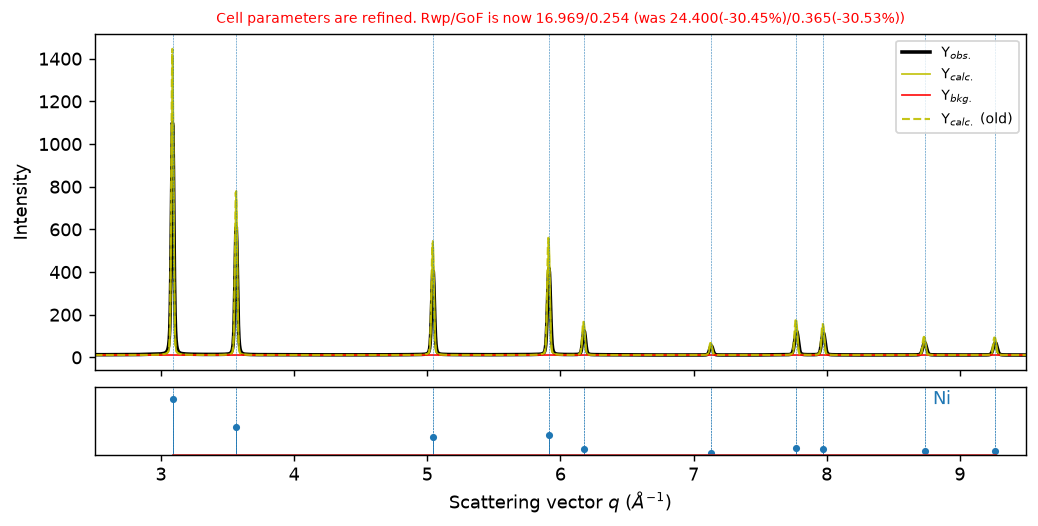

In [8]:
route_a = make_model(cake_sample.ds.i1d, normalize=True, lebail=True,
                     refine_sample_broadening=True)
route_a.refine_background(num_coeffs=5, plot=False)
route_a.refine_cell_parameters(plot=True)

 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 14.416/0.216 (was 16.969(-15.05%)/0.254(-14.83%✨))
 ✅--Size broadening of all phases are refined. Rwp/GoF is now 11.240/0.168 (was 14.416(-22.03%)/0.216(-22.23%✨))
 ✅--Strain broadening of all phases are refined. Rwp/GoF is now 11.234/0.168 (was 11.240(-0.06%)/0.168(-0.06%❗))
Rwp/GoF is now 11.233/0.168 (was 11.234(-0.00%)/0.168(-0.03%❗))
This is still a Le Bail profile fit; structural intensities are enabled next.


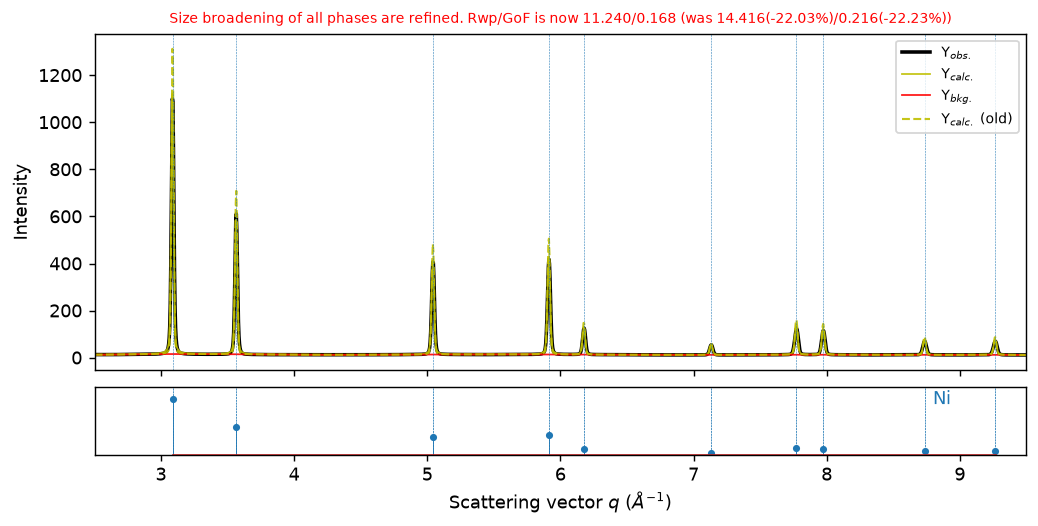

In [9]:
route_a.refine_background(num_coeffs=10, plot=False)
route_a.refine_size_broadening(plot=True)
route_a.refine_strain_broadening(plot=False)
# Like A's original workflow, size/strain flags are cleared after their individual steps.
# Record unbounded trials and do not propagate negative broadening into the final model.
hap_a = route_a.gpx.phases()[0].data['Histograms'][route_a.gpx.histograms()[0].name]
broadening_trials = {'size_um': float(hap_a['Size'][1][0]),
                     'microstrain': float(hap_a['Mustrain'][1][0])}
assert np.all(np.isfinite(list(broadening_trials.values())))
if broadening_trials['size_um'] <= 0:
    hap_a['Size'][1][0] = 10.0
    print('Nonpositive size trial: restore fixed 10 μm reference contribution.')
if broadening_trials['microstrain'] < 0:
    hap_a['Mustrain'][1][0] = 0.0
    print('Negative microstrain trial: fix microstrain=0.')
route_a.ds.attrs['combined_broadening_trials'] = broadening_trials
print(route_a.refine())
print('This is still a Le Bail profile fit; structural intensities are enabled next.')

### 7.1 Switch to structural intensities, then refine the site displacement

Calling `set_LeBail(to=False)` changes the intensity model to Rietveld. As in A, individual
background, cell, size, and strain steps clear their flags. The final background/cell pass
explicitly enables those two groups together. Size/strain are held at their demonstrated
values, with a negative strain trial fixed to zero and a nonpositive size trial replaced
by the fixed reference contribution. Raw trial values are retained in the route summary;
a boundary or reference value is not a microstructural measurement.


 ✅--After setting LeBail refinement to False, Rwp/GoF is now 12.815/0.191 (was 11.233(14.08%)/0.168(14.08%❗))
 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 12.682/0.190 (was 12.815(-1.04%)/0.191(-1.01%))
Uiso trial -0.00131038 Å² is negative: fix Uiso=0 and refit.
Rwp/GoF is now 12.815/0.191 (was 12.682(1.05%)/0.190(1.02%❗))
 ✅--Background with 15 coeffs is refined. Rwp/GoF is now 11.788/0.177 (was 12.815(-8.01%)/0.191(-7.61%))
 ✅--Cell parameters are refined. Rwp/GoF is now 8.640/0.130 (was 11.788(-26.71%)/0.177(-26.68%✨))
route_A_fixed_instrument: GPX/CIF reopened and profile arrays checked.


,quantity,value
0,a_A,3.522539
1,volume_A3,43.708659
2,Uiso_A2,0.000000
3,Rwp_percent_profile,8.640303
4,GOF_relative_weights,0.129690


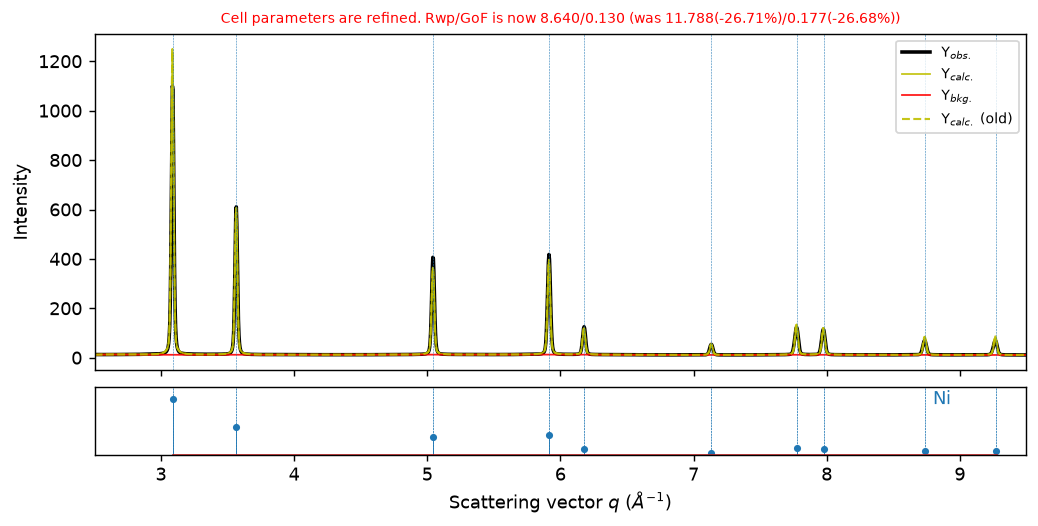

In [10]:
route_a.set_LeBail(to=False, refine=True, plot=False)
trial_u_a = fit_site_displacement(route_a)
route_a.refine_background(num_coeffs=15, set_to_false_after_refinement=False, plot=False)
route_a.refine_cell_parameters(set_to_false_after_refinement=False, plot=True)
for key in ['U', 'V', 'W', 'X', 'Y', 'Zero']:
    assert np.isclose(route_a.gpx.histograms()[0].data['Instrument Parameters'][0][key][1],
                      reference_inst[key][1])
summary_a = save_model(route_a, 'route_A_fixed_instrument',
    'Cake integration; fixed supplied instrument profile; size/strain refinement demonstrated. '
    'Size and strain require independently justified calibration and model assumptions. '
    'A zero-boundary Uiso is not a measured thermal displacement.')

## 8. Another route: Rietveld from the first refinement (B)

Start with the direct 1D profile, without intensity normalization, and disable Le Bail
before any optimizer call. Keep size at 10 μm and microstrain at zero as fixed reference
contributions. Refine scale/background and cell with the supplied profile first, and save
that checkpoint. Then demonstrate Gaussian U/V/W and Lorentzian X/Y profile refinement.
Wavelength, Zero, polarization, Z, and SH/L stay fixed to their supplied values.

These fitted coefficients describe total profile broadening; they do not constitute a new
instrument calibration or an independent size/strain determination.

 ✅--Background with 8 coeffs is refined. Rwp/GoF is 26.698/1.326
 ✅--Cell parameters are refined. Rwp/GoF is now 22.220/1.104 (was 26.698(-16.77%)/1.326(-16.75%✨))


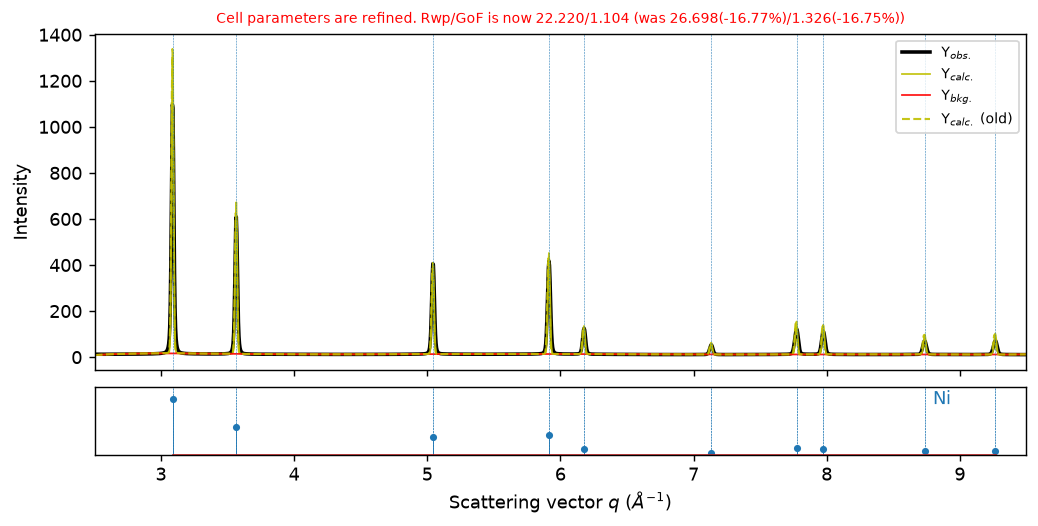

In [11]:
route_b = make_model(direct_sample.ds.i1d, normalize=False, lebail=False)
route_b.refine_background(num_coeffs=8, set_to_false_after_refinement=False, plot=False)
route_b.refine_cell_parameters(set_to_false_after_refinement=False, plot=True)
route_b.export_gpx_to(str(OUT / 'Ni_B_fixed_reference_checkpoint.gpx'))

 ✅--Instrument parameter ['U', 'V', 'W'] is refined. Rwp/GoF is now 9.868/0.491 (was 22.220(-55.59%)/1.104(-55.55%✨))
 ✅--Instrument parameter ['X', 'Y'] is refined. Rwp/GoF is now 7.297/0.363 (was 9.868(-26.06%)/0.491(-26.01%✨))
 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 6.016/0.299 (was 7.297(-17.56%)/0.363(-17.53%✨))
Uiso trial -0.00134652 Å² is negative: fix Uiso=0 and refit.
Rwp/GoF is now 6.227/0.310 (was 6.016(3.52%)/0.299(3.49%❗))
Rwp/GoF is now 6.227/0.310 (was 6.227(-0.01%)/0.310(-0.01%❗))
route_B_direct_Rietveld: GPX/CIF reopened and profile arrays checked.


,quantity,value
0,a_A,3.522678
1,volume_A3,43.713815
2,Uiso_A2,0.000000
3,Rwp_percent_profile,6.226532
4,GOF_relative_weights,0.309823


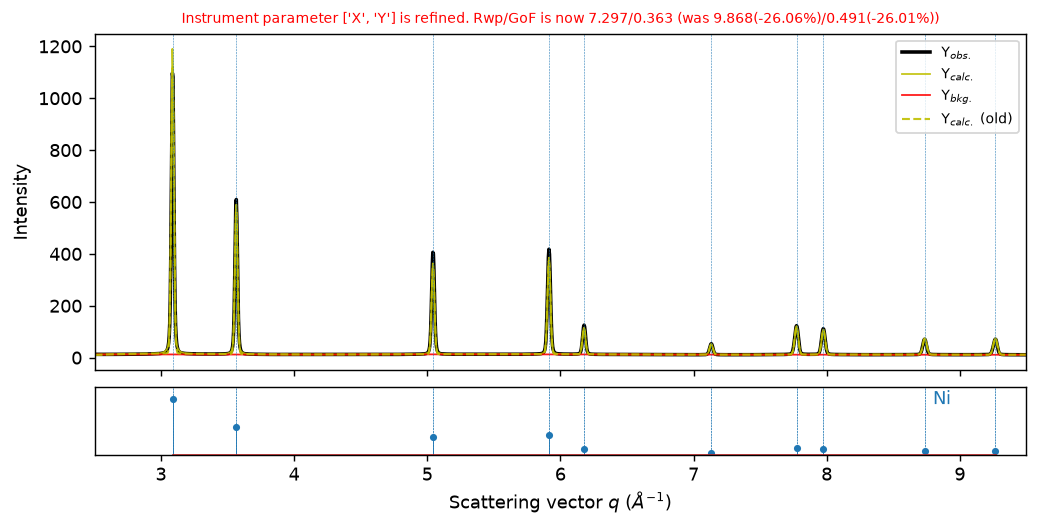

In [12]:
route_b.refine_instrument_parameters(inst_pars_to_refine=['U', 'V', 'W'],
    set_to_false_after_refinement=False, plot=False)
route_b.refine_instrument_parameters(inst_pars_to_refine=['X', 'Y'],
    set_to_false_after_refinement=False, plot=True)
trial_u_b = fit_site_displacement(route_b)
# B's alternative least-squares solver, used for a single final joint pass.
route_b.gpx.data['Controls']['data']['deriv type'] = 'analytic Jacobian'
print(route_b.refine())
for key in ['Lam', 'Zero', 'Polariz.', 'Z', 'SH/L']:
    if key in reference_inst:
        assert np.isclose(route_b.gpx.histograms()[0].data['Instrument Parameters'][0][key][1],
                          reference_inst[key][1])
summary_b = save_model(route_b, 'route_B_direct_Rietveld',
    'Direct 1D integration; Rietveld from the outset; U/V/W and X/Y describe total profile broadening. '
    'Size and strain fixed; Zero and wavelength fixed to the supplied calibration. '
    'Relative weights limit the statistical interpretation of GOF and formal errors.')

## 9. Sequential profile and Zero refinement (C), as an all-in-one workflow

C refines U, V, W, and Zero in separate calls, intersperses background/cell passes, then
switches from Le Bail to Rietveld. The function below preserves that sequence and C's
default helper behavior of clearing flags after each single-parameter refinement.
Its last pass explicitly enables a joint background/cell update.

This is also the automation example: the next cell calls the function from TIFF integration
through export. It creates a fresh object and does not modify routes A or B. Refining Zero
with the cell can correlate the peak-position parameters; this is a demonstration rather
than a replacement for external calibration. No size/strain refinement is combined with
the U/V/W profile adjustment in this route.

In [13]:
def run_all_in_one():
    integrated = exrd()
    integrated.load_xrd_data(
        from_tiff_file=str(BASE / 'Ni.tiff'), poni_file=str(BASE / '_calibration.poni'),
        mask=mask, integrate2d=True, radial_range=[2.0, 9.5],
        delta_q=DELTA_Q, npt_azimuthal=180, method=METHOD, ds_attrs={}, plot=False,
    )
    model = make_model(integrated.ds.i1d, normalize=True, lebail=True)
    model.refine_background(plot=False)  # C's default: 10 coefficients
    model.refine_cell_parameters(plot=False)
    for parameter in ['U', 'V', 'W', 'Zero']:
        model.refine_instrument_parameters(inst_pars_to_refine=[parameter], plot=False)
    model.refine_background(num_coeffs=5, plot=False)
    model.refine_background(num_coeffs=10, plot=False)
    model.refine_cell_parameters(plot=False)
    model.refine_background(num_coeffs=15, plot=False)
    model.set_LeBail(to=False, refine=True, plot=False)
    fit_site_displacement(model)
    model.refine_background(num_coeffs=15, set_to_false_after_refinement=False, plot=False)
    model.refine_cell_parameters(set_to_false_after_refinement=False, plot=False)
    model.plot(title='Route C: sequential U, V, W, Zero → Rietveld')
    summary = save_model(model, 'route_C_all_in_one',
        'Sequential U/V/W/Zero demonstration on a cake profile, followed by structural Rietveld. '
        'Cell and Zero may be correlated. Profile coefficients are not a new instrument calibration. '
        'The workflow is callable for reuse; no route ranking is performed.')
    return model, summary

 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 29.155/0.437 (was 29.155(0.00%)/0.436(0.29%❗))
 ✅--Cell parameters are refined. Rwp/GoF is now 25.618/0.383 (was 29.155(-12.13%)/0.437(-12.36%✨))
 ✅--Instrument parameter ['U'] is refined. Rwp/GoF is now 19.600/0.293 (was 25.618(-23.49%)/0.383(-23.49%✨))
 ✅--Instrument parameter ['V'] is refined. Rwp/GoF is now 15.954/0.238 (was 19.600(-18.60%)/0.293(-18.60%✨))
 ✅--Instrument parameter ['W'] is refined. Rwp/GoF is now 15.043/0.225 (was 15.954(-5.71%)/0.238(-5.71%))
 ✅--Instrument parameter ['Zero'] is refined. Rwp/GoF is now 13.343/0.199 (was 15.043(-11.30%)/0.225(-11.30%✨))
 ✅--Background with 5 coeffs is refined. Rwp/GoF is now 9.977/0.149 (was 13.343(-25.23%)/0.199(-25.14%✨))
 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 8.886/0.133 (was 9.977(-10.93%)/0.149(-10.80%✨))
 ✅--Cell parameters are refined. Rwp/GoF is now 8.612/0.129 (was 8.886(-3.08%)/0.133(-3.33%))
 ✅--Background with 15 coeffs is refined. Rwp/GoF is no

,quantity,value
0,a_A,3.524042
1,volume_A3,43.764645
2,Uiso_A2,0.000000
3,Rwp_percent_profile,10.316742
4,GOF_relative_weights,0.154853


All-in-one demonstration completed.


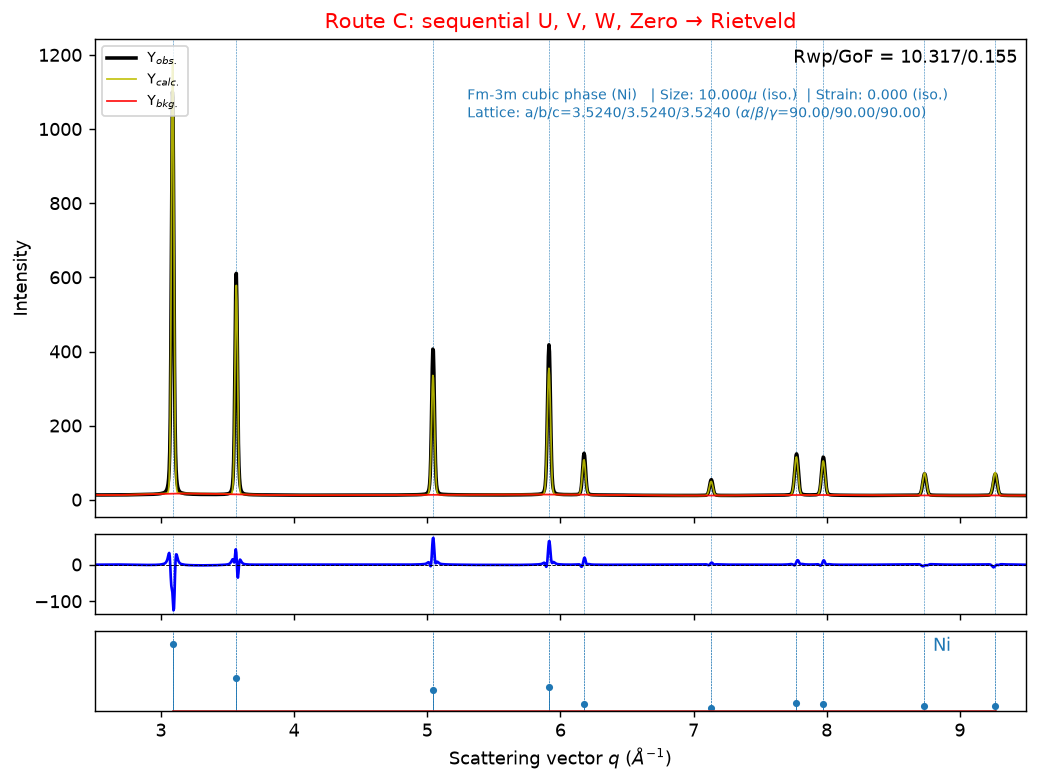

In [14]:
route_c, summary_c = run_all_in_one()
print('All-in-one demonstration completed.')

## 10. Built-in and custom result plotting (A, B, C)

First export easyXRD's built-in final fit view for A. Then use B's histogram-array approach
for a custom observed/calculated/background plot, a difference panel, a positive-only log
view, and three reflection details for B. Each plot belongs to its own route; no curves
from different methods are overlaid or ranked. Standard fit statistics shown here describe
the fitted models; they are not benchmark targets.

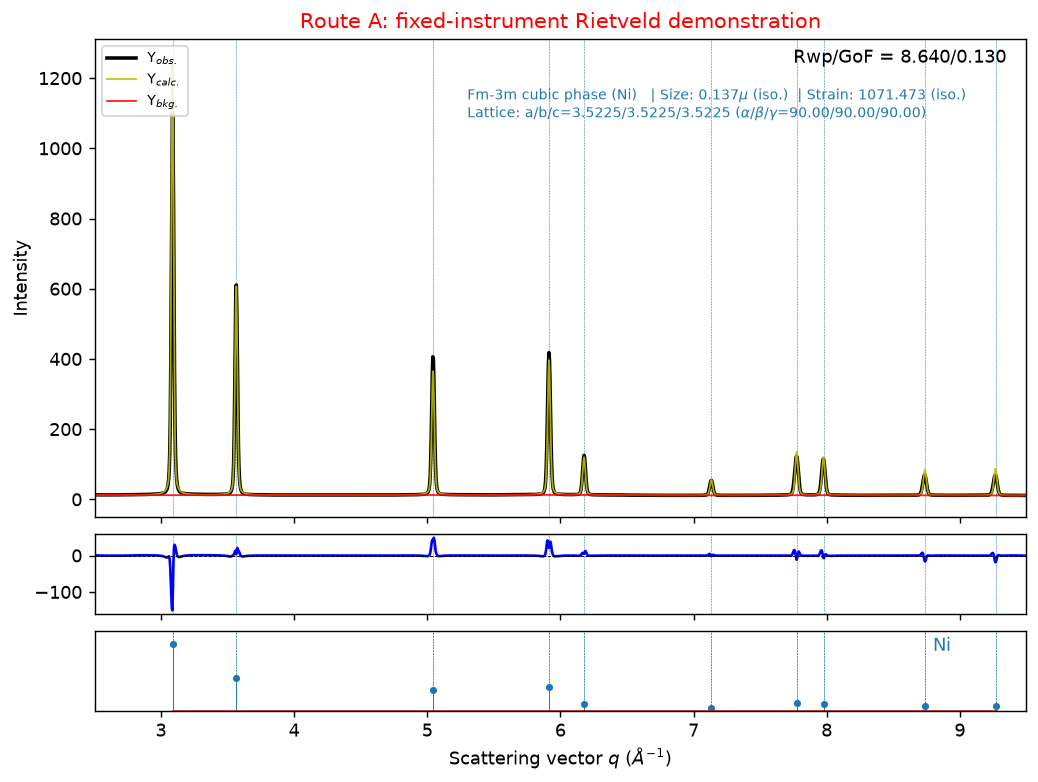

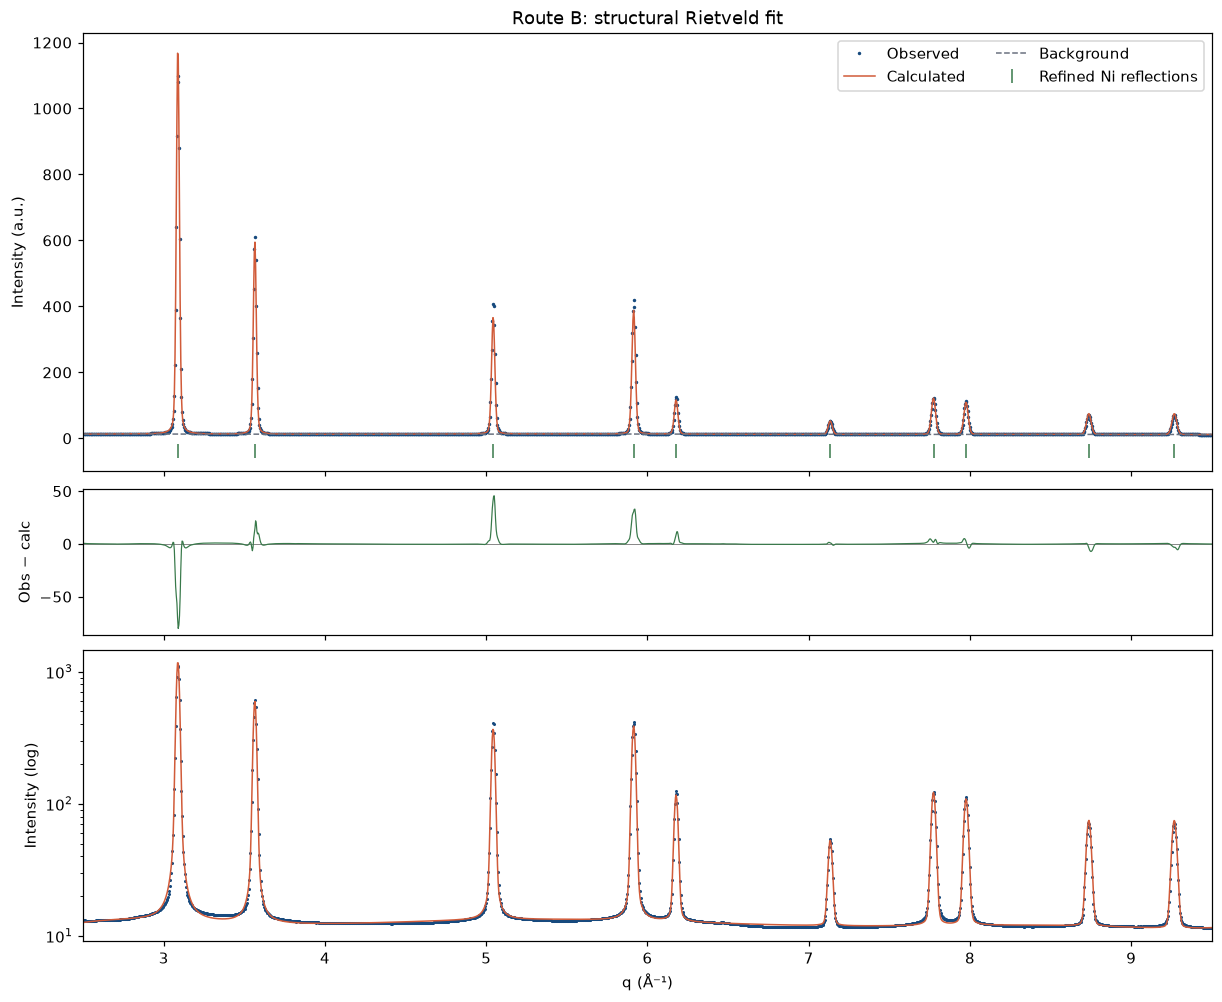

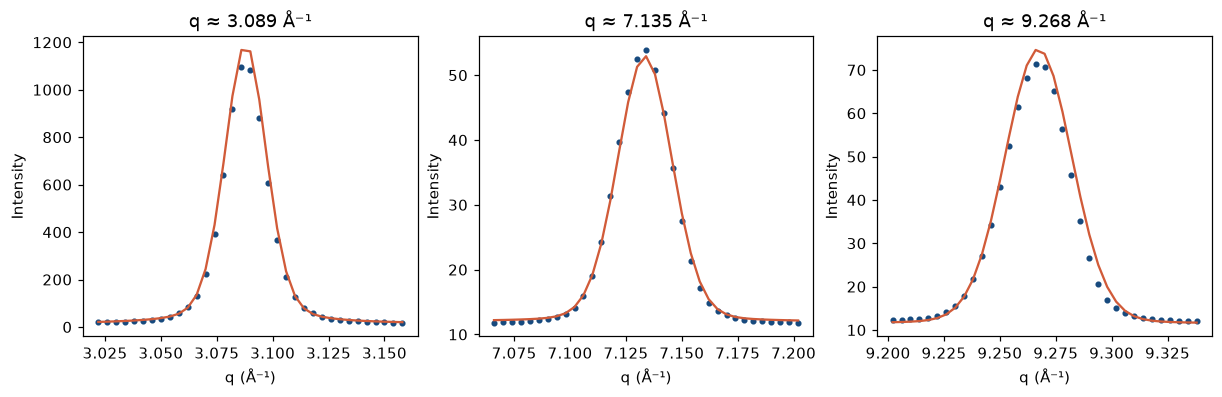

In [15]:
route_a.plot(title='Route A: fixed-instrument Rietveld demonstration',
             export_fig_as=str(OUT / 'route_A_fixed_instrument' / 'Ni_easyXRD_fit.png'))
hist_b, phase_b = validate_model(route_b)
angle = np.asarray(hist_b.getdata('x'))
q_fit = 4 * np.pi * np.sin(np.radians(angle) / 2) / wavelength
y_obs = np.asarray(hist_b.getdata('yobs'))
y_calc = np.asarray(hist_b.getdata('ycalc'))
y_bkg = np.asarray(hist_b.getdata('background'))
refined_structure = Structure.from_str(route_b.ds.attrs['PhaseInd_0_cif'], fmt='cif')
final_peaks = calculator.get_pattern(refined_structure,
    two_theta_range=(float(angle.min()), float(angle.max())))
tick_q = 4 * np.pi * np.sin(np.radians(final_peaks.x) / 2) / wavelength
fig, (ax, difference_ax, log_ax) = plt.subplots(3, 1, figsize=(11, 9), sharex=True,
    gridspec_kw={'height_ratios': [3, 1, 2]})
ax.plot(q_fit, y_obs, '.', ms=2.5, label='Observed', color='#174a7e')
ax.plot(q_fit, y_calc, lw=1, label='Calculated', color='#d15b39')
ax.plot(q_fit, y_bkg, '--', lw=1, label='Background', color='#6b7280')
ax.plot(tick_q, np.full_like(tick_q, -0.035 * y_obs.max()), '|', ms=9,
        label='Refined Ni reflections', color='#38794a')
ax.set(ylabel='Intensity (a.u.)', title='Route B: structural Rietveld fit')
ax.legend(ncol=2)
difference_ax.axhline(0, color='gray', lw=0.6)
difference_ax.plot(q_fit, y_obs - y_calc, lw=0.8, color='#38794a')
difference_ax.set_ylabel('Obs − calc')
log_ax.semilogy(q_fit, np.ma.masked_less_equal(y_obs, 0), '.', ms=2, color='#174a7e')
log_ax.semilogy(q_fit, np.ma.masked_less_equal(y_calc, 0), lw=1, color='#d15b39')
log_ax.set(xlabel='q (Å⁻¹)', ylabel='Intensity (log)', xlim=FIT_RANGE)
fig.savefig(OUT / 'route_B_direct_Rietveld' / 'Ni_custom_fit.png', dpi=180)
plt.show()

assert len(tick_q) >= 3
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, center in zip(axes, [tick_q[0], tick_q[len(tick_q) // 2], tick_q[-1]]):
    keep = abs(q_fit - center) < 0.07
    ax.plot(q_fit[keep], y_obs[keep], 'o', ms=3, color='#174a7e')
    ax.plot(q_fit[keep], y_calc[keep], '-', color='#d15b39')
    ax.set(xlabel='q (Å⁻¹)', ylabel='Intensity', title=f'q ≈ {center:.3f} Å⁻¹')
fig.savefig(OUT / 'route_B_direct_Rietveld' / 'Ni_peak_details.png', dpi=180)
plt.show()

## 11. Provenance and execution checks (B)

Checks cover finite output arrays, positive fit weights, Rietveld mode, saved-project/CIF
reload, and unchanged inputs/source notebooks. No target Rwp, lattice constant, runtime,
or agreement between routes is required. Solver diagnostics remain visible in the outputs.

Model choices are instructional. Background order, broadening, normalization, and intensity
weights affect fitted values. A nonnegative Uiso alone does not establish a reliable thermal
measurement. Consult the supplied calibration and residual plots before interpreting any
microstructural parameter or formal uncertainty.

In [16]:
for model in [route_a, route_b, route_c]:
    validate_model(model)
assert original_hashes == {name: sha256(BASE / name) for name in INPUTS + SOURCES}
provenance = {
    'inputs_and_source_notebooks_sha256': original_hashes,
    'versions': versions,
    'integration': {'wide_q_range_A^-1': Q_RANGE, 'focused_A_q_range_A^-1': FOCUSED_RANGE,
                    'focused_C_q_range_A^-1': [2.0, 9.5], 'fit_q_range_A^-1': FIT_RANGE,
                    'delta_q_A^-1': DELTA_Q, 'method': METHOD, 'npt_azimuthal': 180,
                    'solid_angle_correction': True, 'polarization_factor': None,
                    'extra_dark_flat_or_median_filter': None},
    'models': {label: str(Path(model.gsasii_run_directory).relative_to(BASE))
               for label, model in [('A', route_a), ('B', route_b), ('C', route_c)]},
    'purpose': 'Combine alternative workflows; no benchmarking or route selection.',
}
(OUT / 'Ni_combined_provenance.json').write_text(json.dumps(provenance, indent=2))
display(Markdown('**All three demonstrations completed.** GPX/CIF exports reopened successfully; '
                 'input files and source notebooks are unchanged. Outputs are in '
                 '`Ni_combined_results/`, with a separate folder for each route.'))
print('Named result files:')
for path in sorted(OUT.rglob('*')):
    if path.is_file() and not any(part.startswith('.') or part == 'gsas_work'
                                  for part in path.relative_to(OUT).parts):
        print(path.relative_to(BASE))

**All three demonstrations completed.** GPX/CIF exports reopened successfully; input files and source notebooks are unchanged. Outputs are in `Ni_combined_results/`, with a separate folder for each route.

Named result files:
Ni_combined_results/Ni_B_fixed_reference_checkpoint.gpx
Ni_combined_results/Ni_CIF_reflections.csv
Ni_combined_results/Ni_cake_2theta.xy
Ni_combined_results/Ni_cake_q.xy
Ni_combined_results/Ni_combined_provenance.json
Ni_combined_results/Ni_detector_and_mask.png
Ni_combined_results/Ni_direct_2theta.xy
Ni_combined_results/Ni_direct_2theta.xye
Ni_combined_results/Ni_direct_integrated_profile.csv
Ni_combined_results/Ni_direct_q.xy
Ni_combined_results/route_A_fixed_instrument/Ni_easyXRD_fit.png
Ni_combined_results/route_A_fixed_instrument/Ni_fit_profile.csv
Ni_combined_results/route_A_fixed_instrument/Ni_refined.cif
Ni_combined_results/route_A_fixed_instrument/Ni_refined.gpx
Ni_combined_results/route_A_fixed_instrument/Ni_summary.json
Ni_combined_results/route_B_direct_Rietveld/Ni_custom_fit.png
Ni_combined_results/route_B_direct_Rietveld/Ni_fit_profile.csv
Ni_combined_results/route_B_direct_Rietveld/Ni_peak_details.png
Ni_combined_results/route_B_direct_Rietveld/Ni_ref